In [1]:
%load_ext autoreload
%autoreload 0

import os
import re
import mne
import json
import pyprep
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import paper_style  # two-column paper style for every figure (sizes/font in paper_style.py)
from paper_style import COL_W, enforce_font_sizes
from mne.preprocessing import annotate_muscle_zscore
from mne_icalabel.label_components import label_components

mne.set_log_level('WARNING')

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
raw_dataset = None
RAW_DATASET_NAME = pathlib.Path('data/raw_dataset')
ANNOTATED_DATASET_NAME = pathlib.Path('data/annotated_dataset')
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset')

from scripts.dataset_manager import write_raw_dataset, read_raw_dataset

# Preprocessing

In this file we will perform:

- Preprocessing
  - High/Low/Band-Pass filters
  - Artifact removal
  - Bad electrode interpollation
- Annotation
- Epoching

Which will result in a ready-to-use dataset for further analysis and predictions.

## Data loading

In this first step, we read all the sessions from all the subjects and create a minimally filtered complete dataset. Only frequency filters have been applied to the data at this stage.

## Preprocessing - Filter and removing bad channels

In [3]:
INPUT_DIR = pathlib.Path("data/raw")

def filter_eeg_before_artifact_removal(raw):
    raw.notch_filter(freqs=[50])
    return raw

def filter_eeg_after_artifact_removal(raw):
    raw.filter(l_freq=0.3, h_freq=45.)
    return raw

def artifact_removal(raw):
    raw_hipass = raw.copy().filter(1., 100., picks='eeg')

    ica = mne.preprocessing.ICA(n_components=.99, method='picard', fit_params=dict(ortho=False, extended=True))
    ica.fit(raw_hipass, reject_by_annotation=True)

    # todo check what this does
    labels = label_components(raw_hipass, ica, method='iclabel')

    exclude = [
        i for i, (label, prob) in enumerate(zip(labels['labels'], labels['y_pred_proba']))
        if label not in ('brain', 'other') and prob > 0.8
    ]
    ica.exclude = exclude
    print("Excluding ICA components:", exclude, [labels['labels'][i] for i in exclude])

    ica.apply(raw)

    annot_muscle, scores_muscle = annotate_muscle_zscore(
        raw, ch_type='eeg', threshold=4, min_length_good=0.2,
        filter_freq=(110, 140)
    )
    raw.annotations.append(onset=annot_muscle.onset, duration=annot_muscle.duration, description=annot_muscle.description)
    return raw

def interpolate_bad_channels(raw):
    bad_channels = ['Fz']
    print(f'Bad channels: {bad_channels}')
    raw.info['bads'] = bad_channels
    raw.interpolate_bads(reset_bads=True)
    return raw

MIN_DIST_BETWEEN_EVENTS = 1.8

def add_negative_markers(markers: pd.DataFrame, last_eeg_ts, subject_id):
    rng = np.random.default_rng()
    pinches = markers[markers.EventType == 'PinchLog']
    empty_events = []


    for exp_idx, group in pinches.groupby('ExperimentIndex'):
        ts = np.sort(group.timestamp.values)

        for t1, t2 in zip(ts[:-1], ts[1:]):
            low = t1 + MIN_DIST_BETWEEN_EVENTS
            high = t2 - MIN_DIST_BETWEEN_EVENTS

            if low >= high:
                # gap too small to fit a marker with the required min_dist
                continue

            new_ts = rng.uniform(low, high)

            empty_events.append({
                'timestamp': new_ts,
                'EventType': 'NoPinchLog',
                'ExperimentIndex': exp_idx,
                'PinchType': 'Empty',
            })

    # special case: only a subset of subjects have the random finger movement section at the end of the experiment
    if subject_id >= 33:
        for i in range(5, 66, 5):
            empty_events.append({
                'timestamp': last_eeg_ts - i,
                'EventType': 'NoPinchLog',
                'PinchType': 'FingerMovement',
            })

    new_markers = pd.DataFrame(empty_events)
    print(f"Nb new markers: {len(new_markers)}")
    full_markers = pd.concat([markers, new_markers], ignore_index=True)
    full_markers = full_markers.sort_values(['timestamp'])
    return full_markers

def mark_breaks_as_bad(raw: mne.io.Raw, markers: pd.DataFrame, d = 'BAD_BREAK'):
    i = 1
    onsets = []
    durations = []
    descriptions = []

    while True:
        next_experiment_start = markers[(markers.EventName == 'EXPERIMENT_START') & (markers.ExperimentIndex == i+1)].timestamp.min()
        this_experiment_end = markers[(markers.EventName == 'EXPERIMENT_END') & (markers.ExperimentIndex == i)].timestamp.min()

        if this_experiment_end is np.nan:
            break

        onsets.append(this_experiment_end)
        descriptions.append(d)

        # the last one marks to the end
        if next_experiment_start is np.nan:
            durations.append(raw.times[-10] - this_experiment_end)
            break
        else:
            durations.append(next_experiment_start - this_experiment_end)

        i += 1

    # NB: use annotations.append(), not set_annotations(raw.annotations + new_annotations) -- see
    # the comment in artifact_removal() for why the latter silently double-shifts onsets.
    raw.annotations.append(onset=onsets, duration=durations, description=descriptions)

    return raw


def read_raw_datasets_for_subject(dirname):
    pat = re.compile(r'_(\d{8}_\d{6})\.csv$')
    ts = sorted({m.group(1) for f in pathlib.Path(dirname).glob('*.csv') if (m := pat.search(f.name))})
    dataset = {}

    for i, t in enumerate(ts):
        eeg_csv = pd.read_csv(dirname / f'eeg_Experiment.VIBE.EEG_{t}.csv')
        eeg_metadata = ""
        gaze_csv = pd.read_csv(dirname / f'gaze_Experiment.VIBE.ViveOpenXR_Gaze_{t}.csv')
        gaze_metadata = ""
        markers = pd.read_json(dirname / f'markers_{t}.jsonl', lines=True)
        markers_payload = pd.json_normalize(markers['Payload'])
        markers_experimentconfig = pd.json_normalize(markers['ExperimentConfig'])
        markers_headtracking = pd.json_normalize(markers['HeadTracking'])
        markers = markers.drop(columns=["Payload", "ExperimentConfig", "HeadTracking"]).join(markers_payload).join(markers_experimentconfig).join(markers_headtracking)

        # leave out preparation and tutorial measurements
        start_ts = markers[((markers['EventName'] == 'EXPERIMENT_START') & (markers['ExperimentIndex'] == 1))].timestamp.min()
        markers = markers[markers.timestamp > start_ts]

        markers = add_negative_markers(markers, eeg_csv['timestamp'][len(eeg_csv['timestamp'])-1], int(str(dirname)[-2:]))

        with open(dirname / f'eeg_Experiment.VIBE.EEG_{t}_metadata.txt', 'r') as f:
            eeg_metadata = f.read()
        with open(dirname / f'gaze_Experiment.VIBE.ViveOpenXR_Gaze_{t}_metadata.txt', 'r') as f:
            gaze_metadata = f.read()

        # load frequency from metadata
        match = re.search(r'Info:\s*(\{.*\})', eeg_metadata, re.DOTALL)
        if not match:
            raise ValueError("Info block not found in file")
        sfreq = json.loads(match.group(1))['sfreq']

        eeg_csv_useful_columns = eeg_csv.drop(['timestamp', 'X1', 'X2', 'X3', 'TRG'], axis=1)
        eeg_info = mne.create_info(ch_names=eeg_csv_useful_columns.columns.to_list(), sfreq=sfreq, ch_types='eeg')
        eeg = mne.io.RawArray(eeg_csv_useful_columns.to_numpy().T * 1e-6, eeg_info)
        eeg.rename_channels({"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"})
        eeg = mne.add_reference_channels(eeg.copy().load_data(), "Pz")
        eeg.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing="ignore")
        eeg.set_eeg_reference(ref_channels='average') # reference from Pz to average

        # crop eeg according to the start of the experiment (including some buffer to improve filter quality at the start of the relevant time series)
        timestamps = eeg_csv['timestamp'].to_numpy()
        t_idx = np.searchsorted(timestamps, start_ts - 10)
        timestamps = timestamps[t_idx:]
        eeg = eeg.crop(t_idx / sfreq)
        # align timestamps of the markers to the EEG timeline that starts at T=0
        markers.timestamp -= timestamps[0]

        eeg = mark_breaks_as_bad(eeg, markers)

        eeg_filtered = filter_eeg_before_artifact_removal(eeg.copy())
        eeg_noise_removed = interpolate_bad_channels(eeg_filtered.copy())
        eeg_artifact_removed = artifact_removal(eeg_noise_removed.copy())
        eeg_clean = filter_eeg_after_artifact_removal(eeg_artifact_removed.copy())

        # a veresion with only frequency filters as preprocessing
        eeg_light = filter_eeg_after_artifact_removal(eeg_filtered.copy())

        dataset[f'session_{i+1}'] = {
            'eeg': eeg_clean,
            'eeg_light': eeg_light,
            'eeg_raw': eeg,
            'eeg_filtered': eeg_filtered,
            'ts': eeg_csv['timestamp'].to_numpy(),
            'eeg_metadata': eeg_metadata,
            'gaze': gaze_csv,
            'gaze_metadata': gaze_metadata,
            'markers': markers,
        }


    return dataset

def read_all_raw(ignored_subject_ids: list[str] = []):
    datasets = {}
    dirs = [f for f in os.listdir(INPUT_DIR) if os.path.isdir(INPUT_DIR / f) and f not in ignored_subject_ids]

    for dir in dirs:
        print(f"Processing {dir}")
        datasets[dir] = read_raw_datasets_for_subject(INPUT_DIR / dir)

    return datasets

RECOMPUTE_RAW_DATASET = True
if RECOMPUTE_RAW_DATASET or not RAW_DATASET_NAME.exists():
    raw_dataset = read_all_raw()
    write_raw_dataset(raw_dataset, RAW_DATASET_NAME)
elif raw_dataset is None:
    raw_dataset = read_raw_dataset(RAW_DATASET_NAME)

Processing subject_21
Nb new markers: 168


C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\1139947633.py:156: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  eeg.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing="ignore")


Bad channels: ['Fz']
Excluding ICA components: [] []
Nb new markers: 72
Bad channels: ['Fz']


C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\1139947633.py:156: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  eeg.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing="ignore")


Excluding ICA components: [] []
Processing subject_22
Nb new markers: 167


...

Bad channels: ['Fz']
Excluding ICA components: [0, 3] ['eye blink', 'eye blink']
Nb new markers: 84
Bad channels: ['Fz']


C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\1139947633.py:156: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  eeg.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing="ignore")


Excluding ICA components: [0, 1, 2] ['eye blink', 'eye blink', 'muscle artifact']
Processing subject_40
Nb new markers: 77
Bad channels: ['Fz']


C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\1139947633.py:156: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  eeg.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing="ignore")


Excluding ICA components: [2] ['eye blink']


## Creating epochs

The EEG data is split into epochs all centered around the different markers. Additionally, all events are annotated on the timeline.

In [4]:
T_MIN = -1.7
T_MAX = 0.3
EVENT_IDS = {
    'BlinkLog_L': 0,
    'BlinkLog_R': 1,
    'PinchLog': 2,
    'ExperimentManagerLog': 3,
    'GazeLog': 4,
    'ExperimentLog': 5,
    'NoPinchLog': 6
}

def annotate_and_epoch_eeg(eeg_prop_name='eeg', out_name_epochs=EPOCH_DATASET_NAME, out_name_annotated=ANNOTATED_DATASET_NAME):
    raw_dataset = read_raw_dataset(RAW_DATASET_NAME)
    ds = {}

    for subject in raw_dataset:
        sessions_dataset = {}

        for session in raw_dataset[subject]:
            m = raw_dataset[subject][session]['markers']
            m = m.sort_values('timestamp').reset_index(drop=True)

            # -----------------------------
            # drop pinch double activations
            is_pinch = m['EventType'] == 'PinchLog'
            pinch_df = m[is_pinch].copy()

            # group events closer than .3s
            gap = pinch_df['timestamp'].diff()
            new_group = (gap > 0.3) | gap.isna()
            pinch_df['group'] = new_group.cumsum()

            # keep only the first occurrence per group
            pinch_first = pinch_df.drop_duplicates(subset='group', keep='first').drop(columns='group')
            m = pd.concat([m[~is_pinch], pinch_first]).sort_values('timestamp').reset_index(drop=True)

            # fix timestamp of pinch events if "feedbackIsDelayed" is true. the pinch log is delayed in the original data compared to the real pinch.
            m.loc[(is_pinch & m["feedbackIsDelayed"]), 'timestamp'] -= 0.5

            m = m.sort_values('timestamp').reset_index(drop=True)


            # -----------------
            # build annotations
            # separate blink starts and ends
            blinks_start = []
            blinks_duration = []
            blinks_description = []
            for eye in ['LEFT', 'RIGHT']:
                blinks = m[(m.EventType=='BlinkLog') & (m.Eye==eye)]
                for i in range(len(blinks)):
                    b = blinks.iloc[i]
                    if b.State=='BLINK_START':
                        blinks_start.append(b.timestamp)
                        if (i+1) < len(blinks) and blinks.iloc[i+1].State=='BLINK_END':
                            blinks_duration.append(blinks.iloc[i+1].timestamp - b.timestamp)
                        else:
                            blinks_duration.append(0)
                        blinks_description.append(f'Blink/{eye}')

            blink_annotations = mne.Annotations(
                onset=blinks_start,
                duration=blinks_duration,
                description=blinks_description,
            )

            # pinch events
            pinches = m[m['EventType'].isin(['PinchLog'])]
            pinch_annotations = mne.Annotations(
                onset=pinches['timestamp'].values,
                duration=[0.0] * len(pinches),
                description=pinches['PinchType'].values,
            )

            eeg = raw_dataset[subject][session][eeg_prop_name]
            # NB: use annotations.append(), not set_annotations(eeg.annotations + ...). Since
            # orig_time is None here (eeg.info['meas_date'] is None), set_annotations() shifts
            # every onset it receives by eeg.first_time. Calling it again on top of annotations
            # that were already attached via set_annotations() (BAD_BREAK, muscle) double-shifts
            # them -- that's what was pushing annotations past the end of the recording and
            # triggering the "omitted annotation(s) outside data range" warnings.
            eeg.annotations.append(onset=blink_annotations.onset, duration=blink_annotations.duration, description=blink_annotations.description)
            eeg.annotations.append(onset=pinch_annotations.onset, duration=pinch_annotations.duration, description=pinch_annotations.description)

            # -------------------
            # events for epoching
            m['sample'] = (m.timestamp * 300).round().astype(int) + eeg.first_samp
            m.loc[(m.EventType == 'BlinkLog') & (m.Eye == 'LEFT'), 'EventType'] = 'BlinkLog_L'
            m.loc[(m.EventType == 'BlinkLog') & (m.Eye == 'RIGHT'), 'EventType'] = 'BlinkLog_R'

            events = np.array([
                m['sample'].to_list(),
                [0] * m['sample'].shape[0],
                [EVENT_IDS[e] for e in m['EventType']],
            ]).T.astype(int)

            # increment the duplicates' sample index by 1
            unique_rows, counts = np.unique(events[:, 0], return_counts=True)
            duplicated_values = unique_rows[counts > 1]
            while len(duplicated_values > 0):
                events_df = pd.DataFrame(events)
                offset = events_df.groupby(0).cumcount()
                events_df[0] = events_df[0] + offset
                events = events_df.to_numpy()
                unique_rows, counts = np.unique(events[:, 0], return_counts=True)
                duplicated_values = unique_rows[counts > 1]

            events = events.astype(int)
            epochs = mne.Epochs(eeg, events, event_id=EVENT_IDS, metadata=m, tmin=T_MIN, tmax=T_MAX, preload=True)
            sessions_dataset[session] = epochs
        ds[subject] = sessions_dataset

    write_raw_dataset(raw_dataset, out_name_annotated)
    write_raw_dataset(ds, out_name_epochs)
    return ds, raw_dataset

epoched_dataset, annotated_dataset = annotate_and_epoch_eeg()
epoched_dataset, annotated_dataset = annotate_and_epoch_eeg(eeg_prop_name='eeg_light',
                                                            out_name_annotated=pathlib.Path('data/annotated_dataset_light'),
                                                            out_name_epochs=pathlib.Path('data/epoch_dataset_light'))

C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\2920564387.py:110: RuntimeWarning: 1 event is outside the data range; the corresponding epoch cannot be created. This can happen if the events were created at a different sampling frequency, or have entries before first_samp.
  epochs = mne.Epochs(eeg, events, event_id=EVENT_IDS, metadata=m, tmin=T_MIN, tmax=T_MAX, preload=True)
C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\2920564387.py:110: RuntimeWarning: 1 event is outside the data range; the corresponding epoch cannot be created. This can happen if the events were created at a different sampling frequency, or have entries before first_samp.
  epochs = mne.Epochs(eeg, events, event_id=EVENT_IDS, metadata=m, tmin=T_MIN, tmax=T_MAX, preload=True)
C:\Users\nicol\AppData\Local\Temp\ipykernel_41756\2920564387.py:110: RuntimeWarning: 4 events are outside the data range; the corresponding epochs cannot be created. This can happen if the events were created at a different sampling frequ

## Timing sanity check

> for timing sanity check to work, the epochs must be created based on the raw dataset, not the filtered one.

As a quick sanity check to the timing, the blink value can be used. Blinks have an expected duration of .2 to .4s, the peak activation in the frontal channels is to be expected in the midway of the blink.

The following diagram cleanly shows the start of the measured blink to be right around the rising edge of the frontal EEG channels.

findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXSizeOneSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeTwoSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeThreeSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFourSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight 300 for cmmi10, now using 400.
findfont: Failed to find font weight 300 for cmsy10, now using 400.
findfont: Failed to find font weight 300 for cmr10, now using 400.
findfont: Failed to find font weight 300 for cmtt10, now using 400.
findfont: Failed to find font weight 300 for cm

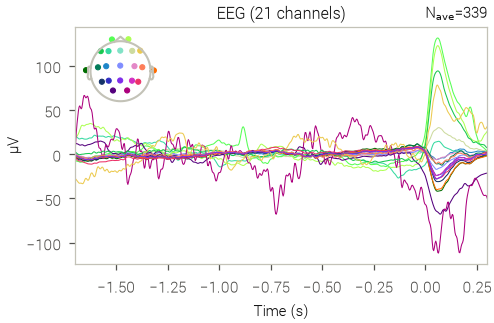

In [5]:
fig, ax = plt.subplots(figsize=(COL_W, 2.2), layout='constrained')
_ = epoched_dataset['subject_24']['session_1']['BlinkLog_L']['State == "BLINK_START"'].average().plot(axes=ax, show=False)
enforce_font_sizes(fig)
plt.show()

In [6]:
markers = raw_dataset['subject_21']['session_1']['markers']
markers[(markers.EventName == 'EXPERIMENT_END') & (markers.ExperimentIndex == 20)].timestamp.min()

nan

In [7]:
markers[markers.EventType == 'NoPinchLog']

,UnityTimestamp,EventType,EventName,Severity,ExperimentName,ExperimentIndex,timestamp,stream,Eye,State,...,GazeOrigin.z,GazeDirection.x,GazeDirection.y,GazeDirection.z,HeadPosition.x,HeadPosition.y,HeadPosition.z,HeadForward.x,HeadForward.y,HeadForward.z
1411,NaN,NoPinchLog,NaN,NaN,NaN,1,16.558913,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1412,NaN,NoPinchLog,NaN,NaN,NaN,1,21.283270,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1413,NaN,NoPinchLog,NaN,NaN,NaN,1,29.257660,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1414,NaN,NoPinchLog,NaN,NaN,NaN,1,35.261799,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1415,NaN,NoPinchLog,NaN,NaN,NaN,1,41.731677,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1574,NaN,NoPinchLog,NaN,NaN,NaN,12,1444.612378,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1575,NaN,NoPinchLog,NaN,NaN,NaN,12,1449.998484,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1576,NaN,NoPinchLog,NaN,NaN,NaN,12,1459.613000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1577,NaN,NoPinchLog,NaN,NaN,NaN,12,1466.070178,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
